In [1]:

import pandas as pd
import numpy as np
import os
from pathlib import Path


In [2]:

# Define the project data directory
data_dir = Path("D:/Data Science/Internship and Certificate/Infosys/Precessed_Dataset")

# Load route overlap data
overlap_path = data_dir / "D:/Data Science/Internship and Certificate/Infosys/Precessed_Dataset/overlap_df.csv"

# Load route features
features_path = data_dir / "D:/Data Science/Internship and Certificate/Infosys/Precessed_Dataset/route_features.csv"

# Check whether files exist
if not overlap_path.exists():
    raise FileNotFoundError(
        f"Could not find: {overlap_path.resolve()}"
    )

if not features_path.exists():
    raise FileNotFoundError(
        f"Could not find: {features_path.resolve()}"
    )

# Read CSV files
overlap_df = pd.read_csv(overlap_path)
route_features = pd.read_csv(features_path)

print("Datasets loaded successfully!")
print("Overlap dataset shape:", overlap_df.shape)
print("Route features shape:", route_features.shape)


Datasets loaded successfully!
Overlap dataset shape: (207692, 7)
Route features shape: (2403, 11)


In [3]:

print("Overlap Dataset Columns:")
print(overlap_df.columns.tolist())

print("\nFirst 10 Records:")
display(overlap_df.head(10))

print("\nDataset Information:")
overlap_df.info()


Overlap Dataset Columns:
['route1', 'route2', 'shared_stops', 'route1_stops', 'route2_stops', 'total_unique_stops', 'overlap_percentage']

First 10 Records:


,route1,route2,shared_stops,route1_stops,route2_stops,total_unique_stops,overlap_percentage
0,10040,10553,171,196,197,222,77.027027
1,10066,10423,159,175,176,192,82.812500
2,1646,962,102,102,102,102,100.000000
3,1365,362,94,94,94,94,100.000000
4,1005,1872,92,92,92,92,100.000000
5,1742,612,84,84,84,84,100.000000
6,1365,962,79,94,102,117,67.521368
7,1646,362,79,102,94,117,67.521368
8,362,962,79,94,102,117,67.521368
9,1365,1646,79,94,102,117,67.521368



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 207692 entries, 0 to 207691
Data columns (total 7 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   route1              207692 non-null  int64  
 1   route2              207692 non-null  int64  
 2   shared_stops        207692 non-null  int64  
 3   route1_stops        207692 non-null  int64  
 4   route2_stops        207692 non-null  int64  
 5   total_unique_stops  207692 non-null  int64  
 6   overlap_percentage  207692 non-null  float64
dtypes: float64(1), int64(6)
memory usage: 11.1 MB


In [4]:
#Validate and prepare the columns

# Standardize column names
overlap_df.columns = (
    overlap_df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

# Possible column name variations
column_aliases = {
    "route_id_1": ["route_id_1", "route1", "route_a"],
    "route_id_2": ["route_id_2", "route2", "route_b"],
    "shared_stops": ["shared_stops", "common_stops"],
    "overlap_percentage": [
        "overlap_percentage",
        "overlap_percent",
        "overlap_pct",
        "jaccard_similarity"
    ]
}

# Find matching columns
selected_columns = {}

for standard_name, alternatives in column_aliases.items():
    matches = [
        col for col in alternatives
        if col in overlap_df.columns
    ]

    if not matches:
        raise ValueError(
            f"Missing column for {standard_name}. "
            f"Available columns: {overlap_df.columns.tolist()}"
        )

    selected_columns[standard_name] = matches[0]

# Rename selected columns
overlap_df = overlap_df.rename(
    columns={
        actual: standard
        for standard, actual in selected_columns.items()
    }
)

# Convert numeric columns
overlap_df["shared_stops"] = pd.to_numeric(
    overlap_df["shared_stops"], errors="coerce"
)

overlap_df["overlap_percentage"] = pd.to_numeric(
    overlap_df["overlap_percentage"], errors="coerce"
)

# Remove incomplete records
overlap_df = overlap_df.dropna(
    subset=[
        "route_id_1",
        "route_id_2",
        "shared_stops",
        "overlap_percentage"
    ]
).copy()

# Handle overlap represented as a decimal (0 to 1)
if (
    not overlap_df.empty
    and overlap_df["overlap_percentage"].max() <= 1
):
    overlap_df["overlap_percentage"] *= 100

# Check the prepared data
print("Prepared overlap dataset:")
display(overlap_df.head())

print("\nOverlap percentage range:")
print(
    overlap_df["overlap_percentage"].min(),
    "to",
    overlap_df["overlap_percentage"].max()
)


Prepared overlap dataset:


,route_id_1,route_id_2,shared_stops,route1_stops,route2_stops,total_unique_stops,overlap_percentage
0,10040,10553,171,196,197,222,77.027027
1,10066,10423,159,175,176,192,82.812500
2,1646,962,102,102,102,102,100.000000
3,1365,362,94,94,94,94,100.000000
4,1005,1872,92,92,92,92,100.000000



Overlap percentage range:
0.3610108303249097 to 100.0


In [5]:
#Identify highly overlapping routes

def classify_overlap(overlap):
    if overlap >= 70:
        return "High"
    elif overlap >= 40:
        return "Moderate"
    else:
        return "Low"


overlap_df["overlap_category"] = (
    overlap_df["overlap_percentage"]
    .apply(classify_overlap)
)

print("Overlap Categories:")
print(overlap_df["overlap_category"].value_counts())

display(overlap_df.head(10))


Overlap Categories:
overlap_category
Low         204749
Moderate      2586
High           357
Name: count, dtype: int64


,route_id_1,route_id_2,shared_stops,route1_stops,route2_stops,total_unique_stops,overlap_percentage,overlap_category
0,10040,10553,171,196,197,222,77.027027,High
1,10066,10423,159,175,176,192,82.812500,High
2,1646,962,102,102,102,102,100.000000,High
3,1365,362,94,94,94,94,100.000000,High
4,1005,1872,92,92,92,92,100.000000,High
5,1742,612,84,84,84,84,100.000000,High
6,1365,962,79,94,102,117,67.521368,Moderate
7,1646,362,79,102,94,117,67.521368,Moderate
8,362,962,79,94,102,117,67.521368,Moderate
9,1365,1646,79,94,102,117,67.521368,Moderate


In [6]:
#Generate route merging recommendations

# Create a copy for recommendation generation
merging_suggestions = overlap_df.copy()

# Generate recommendation
def generate_merge_recommendation(row):

    if row["overlap_percentage"] >= 70:
        return "Investigate Possible Route Merging"

    elif row["overlap_percentage"] >= 40:
        return "Review Shared Route Corridor"

    else:
        return "No Merging Recommendation"


merging_suggestions["recommendation"] = (
    merging_suggestions.apply(
        generate_merge_recommendation,
        axis=1
    )
)

# Add explanation
def generate_reason(row):

    if row["overlap_percentage"] >= 70:
        return (
            f"High overlap of "
            f"{row['overlap_percentage']:.2f}% "
            f"with {int(row['shared_stops'])} shared stops."
        )

    elif row["overlap_percentage"] >= 40:
        return (
            f"Moderate overlap of "
            f"{row['overlap_percentage']:.2f}%. "
            "Review the shared corridor."
        )

    else:
        return "Insufficient overlap for a merging recommendation."


merging_suggestions["reason"] = (
    merging_suggestions.apply(
        generate_reason,
        axis=1
    )
)

display(
    merging_suggestions[
        [
            "route_id_1",
            "route_id_2",
            "shared_stops",
            "overlap_percentage",
            "recommendation",
            "reason"
        ]
    ].head(15)
)


,route_id_1,route_id_2,shared_stops,overlap_percentage,recommendation,reason
0,10040,10553,171,77.027027,Investigate Possible Route Merging,High overlap of 77.03% with 171 shared stops.
1,10066,10423,159,82.812500,Investigate Possible Route Merging,High overlap of 82.81% with 159 shared stops.
2,1646,962,102,100.000000,Investigate Possible Route Merging,High overlap of 100.00% with 102 shared stops.
3,1365,362,94,100.000000,Investigate Possible Route Merging,High overlap of 100.00% with 94 shared stops.
4,1005,1872,92,100.000000,Investigate Possible Route Merging,High overlap of 100.00% with 92 shared stops.
5,1742,612,84,100.000000,Investigate Possible Route Merging,High overlap of 100.00% with 84 shared stops.
6,1365,962,79,67.521368,Review Shared Route Corridor,Moderate overlap of 67.52%. Review the shared ...
7,1646,362,79,67.521368,Review Shared Route Corridor,Moderate overlap of 67.52%. Review the shared ...
8,362,962,79,67.521368,Review Shared Route Corridor,Moderate overlap of 67.52%. Review the shared ...
9,1365,1646,79,67.521368,Review Shared Route Corridor,Moderate overlap of 67.52%. Review the shared ...


In [7]:
#Analyse the highly overlapping route pairs

high_overlap_routes = merging_suggestions[
    merging_suggestions["overlap_percentage"] >= 70
].copy()

high_overlap_routes = high_overlap_routes.sort_values(
    by="overlap_percentage",
    ascending=False
)

print(
    "Total route pairs:",
    len(merging_suggestions)
)

print(
    "High overlap route pairs:",
    len(high_overlap_routes)
)

print("\nTop 20 Potential Merging Candidates:")

display(
    high_overlap_routes[
        [
            "route_id_1",
            "route_id_2",
            "shared_stops",
            "overlap_percentage",
            "recommendation"
        ]
    ].head(20)
)


Total route pairs: 207692
High overlap route pairs: 357

Top 20 Potential Merging Candidates:


,route_id_1,route_id_2,shared_stops,overlap_percentage,recommendation
7106,136,710,19,100.0,Investigate Possible Route Merging
15163,10524,1228,14,100.0,Investigate Possible Route Merging
755,1484,783,35,100.0,Investigate Possible Route Merging
258,10488,2036,42,100.0,Investigate Possible Route Merging
241,10496,10608,42,100.0,Investigate Possible Route Merging
10134,10432,1714,17,100.0,Investigate Possible Route Merging
10221,10480,1720,17,100.0,Investigate Possible Route Merging
10301,10480,10495,17,100.0,Investigate Possible Route Merging
10709,10495,1720,17,100.0,Investigate Possible Route Merging
10769,407,420,17,100.0,Investigate Possible Route Merging


In [8]:
#Add route characteristics

# Select useful route characteristics
route_info = route_features[
    [
        "route_id",
        "avg_route_length_km",
        "total_trips",
        "total_unique_stops"
    ]
].drop_duplicates(subset="route_id").copy()

# Prepare characteristics for route 1
route_info_1 = route_info.rename(
    columns={
        "route_id": "route_id_1",
        "avg_route_length_km": "route_1_length_km",
        "total_trips": "route_1_total_trips",
        "total_unique_stops": "route_1_unique_stops"
    }
)

# Prepare characteristics for route 2
route_info_2 = route_info.rename(
    columns={
        "route_id": "route_id_2",
        "avg_route_length_km": "route_2_length_km",
        "total_trips": "route_2_total_trips",
        "total_unique_stops": "route_2_unique_stops"
    }
)

# Join route characteristics
merging_suggestions = merging_suggestions.merge(
    route_info_1,
    on="route_id_1",
    how="left"
)

merging_suggestions = merging_suggestions.merge(
    route_info_2,
    on="route_id_2",
    how="left"
)

print("Route characteristics added successfully!")

display(merging_suggestions.head(10))


Route characteristics added successfully!


,route_id_1,route_id_2,shared_stops,route1_stops,route2_stops,total_unique_stops,overlap_percentage,overlap_category,recommendation,reason,route_1_length_km,route_1_total_trips,route_1_unique_stops,route_2_length_km,route_2_total_trips,route_2_unique_stops
0,10040,10553,171,196,197,222,77.027027,High,Investigate Possible Route Merging,High overlap of 77.03% with 171 shared stops.,95.261151,12,196,94.372678,55,197
1,10066,10423,159,175,176,192,82.812500,High,Investigate Possible Route Merging,High overlap of 82.81% with 159 shared stops.,94.599351,29,175,95.313566,35,176
2,1646,962,102,102,102,102,100.000000,High,Investigate Possible Route Merging,High overlap of 100.00% with 102 shared stops.,57.498710,8,102,57.498710,8,102
3,1365,362,94,94,94,94,100.000000,High,Investigate Possible Route Merging,High overlap of 100.00% with 94 shared stops.,56.954402,22,94,56.954402,16,94
4,1005,1872,92,92,92,92,100.000000,High,Investigate Possible Route Merging,High overlap of 100.00% with 92 shared stops.,43.093947,35,92,43.093947,9,92
5,1742,612,84,84,84,84,100.000000,High,Investigate Possible Route Merging,High overlap of 100.00% with 84 shared stops.,45.684135,117,84,45.684135,118,84
6,1365,962,79,94,102,117,67.521368,Moderate,Review Shared Route Corridor,Moderate overlap of 67.52%. Review the shared ...,56.954402,22,94,57.498710,8,102
7,1646,362,79,102,94,117,67.521368,Moderate,Review Shared Route Corridor,Moderate overlap of 67.52%. Review the shared ...,57.498710,8,102,56.954402,16,94
8,362,962,79,94,102,117,67.521368,Moderate,Review Shared Route Corridor,Moderate overlap of 67.52%. Review the shared ...,56.954402,16,94,57.498710,8,102
9,1365,1646,79,94,102,117,67.521368,Moderate,Review Shared Route Corridor,Moderate overlap of 67.52%. Review the shared ...,56.954402,22,94,57.498710,8,102


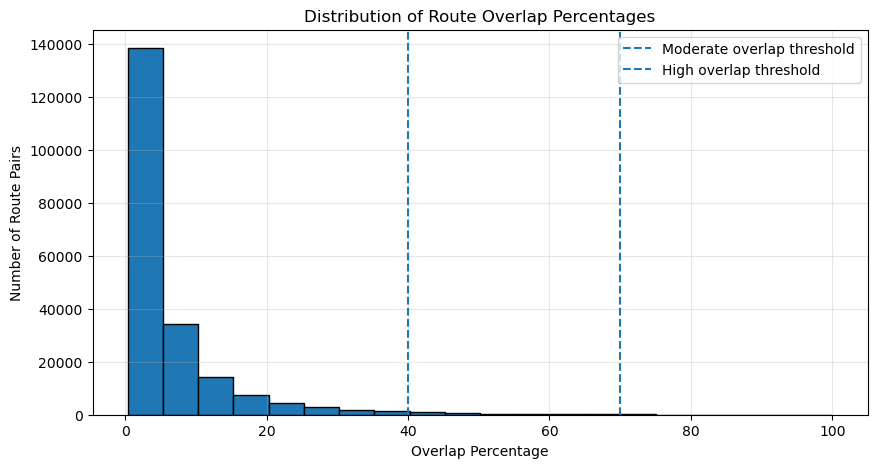

In [9]:
#Visualize the recommendations

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    merging_suggestions["overlap_percentage"],
    bins=20,
    edgecolor="black"
)

plt.axvline(
    40,
    linestyle="--",
    label="Moderate overlap threshold"
)

plt.axvline(
    70,
    linestyle="--",
    label="High overlap threshold"
)

plt.title("Distribution of Route Overlap Percentages")
plt.xlabel("Overlap Percentage")
plt.ylabel("Number of Route Pairs")
plt.legend()
plt.grid(alpha=0.3)

plt.show()


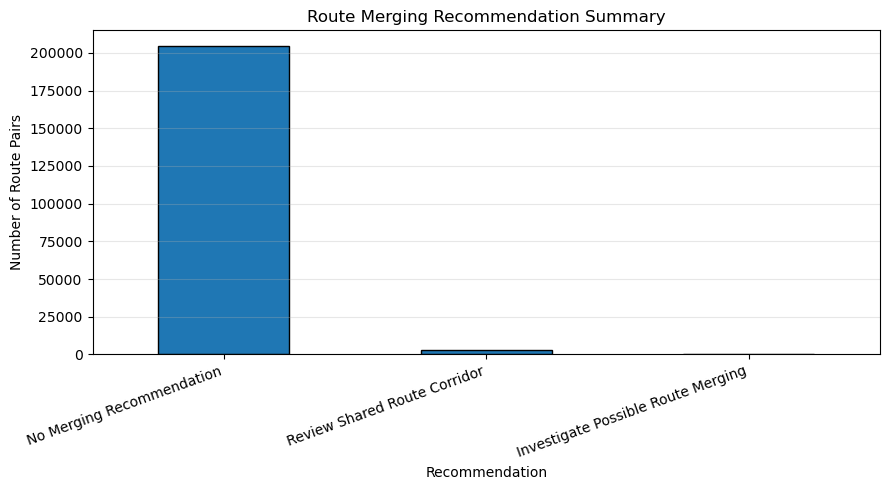

In [10]:

recommendation_counts = (
    merging_suggestions["recommendation"]
    .value_counts()
)

plt.figure(figsize=(9, 5))

recommendation_counts.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Route Merging Recommendation Summary")
plt.xlabel("Recommendation")
plt.ylabel("Number of Route Pairs")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [11]:
#Part 2 – Route Splitting Optimization

In [24]:
# Project directories
data_dir = Path("D:/Data Science/Internship and Certificate/Infosys/Precessed_Dataset")
dataset_dir = Path("D:\Data Science\Internship and Certificate\Infosys\Dataset\bus_delhi")

# Load route features
features_path = data_dir / "route_features.csv"

if not features_path.exists():
    raise FileNotFoundError(
        f"Route features not found: {features_path.resolve()}"
    )

split_features = pd.read_csv(features_path)

print("Route features loaded successfully!")
print("Dataset shape:", split_features.shape)

display(split_features.head())

Route features loaded successfully!
Dataset shape: (2403, 11)


,route_id,agency_id,route_type,avg_route_length_km,total_trips,total_scheduled_stop_records,active_hours,avg_hourly_stop_records,total_unique_stops,overlapping_routes,total_shared_stops
0,142,DIMTS,3,17.260346,33,825,18,45.833333,25,196,705
1,10001,DIMTS,3,35.080606,30,2250,16,140.625000,75,174,929
2,362,DIMTS,3,56.954402,16,1504,16,94.000000,94,356,2247
3,274,DIMTS,3,21.042495,20,860,16,53.750000,43,230,1404
4,10386,DIMTS,3,12.252268,23,713,19,37.526316,31,131,829


In [19]:
#Inspect route characteristics
required_columns = [
    "route_id",
    "avg_route_length_km",
    "total_unique_stops",
    "total_trips"
]

missing_columns = [
    col for col in required_columns
    if col not in split_features.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Convert numeric columns
for col in [
    "avg_route_length_km",
    "total_unique_stops",
    "total_trips"
]:
    split_features[col] = pd.to_numeric(
        split_features[col],
        errors="coerce"
    )

split_features = split_features.dropna(
    subset=required_columns
).copy()

split_features = split_features.drop_duplicates(
    subset="route_id"
)

print("Route length statistics:")
display(
    split_features[
        [
            "avg_route_length_km",
            "total_unique_stops",
            "total_trips"
        ]
    ].describe()
)

Route length statistics:


,avg_route_length_km,total_unique_stops,total_trips
count,2403.000000,2403.000000,2403.000000
mean,23.615182,41.055347,37.200583
std,13.787119,17.922021,41.009652
min,0.873004,2.000000,1.000000
25%,16.161594,30.000000,10.000000
50%,22.598093,42.000000,23.000000
75%,28.756294,52.000000,47.000000
max,184.409280,197.000000,318.000000


In [20]:
#Identify unusually long routes


In [21]:
# Calculate 90th percentile of route length
length_threshold = split_features[
    "avg_route_length_km"
].quantile(0.90)

# Calculate median stop count
stop_threshold = split_features[
    "total_unique_stops"
].median()

# Identify routes above the length threshold
long_routes = split_features[
    split_features["avg_route_length_km"] >= length_threshold
].copy()

# Check stop count as an additional complexity indicator
long_routes["high_stop_count"] = (
    long_routes["total_unique_stops"] >= stop_threshold
)

print("90th percentile route length:", round(length_threshold, 2), "km")
print("Median unique stops:", round(stop_threshold, 2))

print("Long routes identified:", len(long_routes))

display(
    long_routes[
        [
            "route_id",
            "avg_route_length_km",
            "total_unique_stops",
            "total_trips",
            "high_stop_count"
        ]
    ].head(20)
)

90th percentile route length: 35.0 km
Median unique stops: 42.0
Long routes identified: 241


,route_id,avg_route_length_km,total_unique_stops,total_trips,high_stop_count
1,10001,35.080606,75,30,True
2,362,56.954402,94,16,True
12,10389,36.211691,73,16,True
26,1365,56.954402,94,22,True
37,2045,40.754227,74,38,True
38,202,37.406540,54,10,True
48,858,36.400659,49,1,True
62,474,38.802558,71,38,True
90,2101,46.261227,57,1,True
158,1872,43.093947,92,9,True


In [22]:
#Identify routes suitable for split investigation
split_candidates = long_routes[
    long_routes["high_stop_count"]
].copy()

split_candidates = split_candidates.sort_values(
    by=[
        "avg_route_length_km",
        "total_unique_stops"
    ],
    ascending=False
)

print(
    "Potential route splitting candidates:",
    len(split_candidates)
)

display(
    split_candidates[
        [
            "route_id",
            "avg_route_length_km",
            "total_unique_stops",
            "total_trips"
        ]
    ].head(20)
)

Potential route splitting candidates: 223


,route_id,avg_route_length_km,total_unique_stops,total_trips
1720,5321,154.444932,48,63
2187,5788,153.563040,47,69
1932,5533,121.214129,59,2
1917,5518,120.991390,66,4
2006,5607,117.034234,62,12
1933,5534,108.006251,48,134
1934,5535,107.374206,51,5
1535,5136,104.274193,58,28
521,10070,101.709382,43,39
1539,5140,97.795482,59,12


In [26]:
from pathlib import Path
import pandas as pd

# Define the dataset folder
dataset_dir = Path(
    r"D:\Data Science\Internship and Certificate\Infosys\Dataset\bus_delhi"
)

# Define file paths
trips_path = dataset_dir / "trips.txt"
stop_times_path = dataset_dir / "stop_times.txt"

# Check whether files exist
if not trips_path.exists():
    raise FileNotFoundError(f"Trips file not found: {trips_path}")

if not stop_times_path.exists():
    raise FileNotFoundError(f"Stop times file not found: {stop_times_path}")

# Load trips data
trips_df = pd.read_csv(
    trips_path,
    usecols=["trip_id", "route_id"]
)

# Keep only trips belonging to candidate routes
candidate_route_ids = set(
    split_candidates["route_id"].astype(str)
)

trips_df["route_id"] = trips_df["route_id"].astype(str)

candidate_trips = trips_df[
    trips_df["route_id"].isin(candidate_route_ids)
].copy()

print("Trips data loaded successfully!")
print("Total trips:", len(trips_df))
print("Candidate trips:", len(candidate_trips))

display(candidate_trips.head())

Trips data loaded successfully!
Total trips: 89393
Candidate trips: 7316


,route_id,trip_id
33,10001,10001_11_30
34,10001,10001_12_10
35,10001,10001_12_50
36,10001,10001_18_50
37,10001,10001_16_50


In [28]:
candidate_trip_ids = set(
    candidate_trips["trip_id"].astype(str)
)

stop_sequence_parts = []

# Read large stop_times file in chunks
for chunk in pd.read_csv(
    stop_times_path,
    usecols=["trip_id", "stop_id", "stop_sequence"],
    chunksize=500000,
    dtype={"trip_id": str, "stop_id": str}
):

    chunk = chunk[
        chunk["trip_id"].isin(candidate_trip_ids)
    ]

    if not chunk.empty:
        stop_sequence_parts.append(chunk)

if not stop_sequence_parts:
    raise ValueError(
        "No stop-time records found for candidate routes."
    )

candidate_stop_times = pd.concat(
    stop_sequence_parts,
    ignore_index=True
)

candidate_stop_times["stop_sequence"] = pd.to_numeric(
    candidate_stop_times["stop_sequence"],
    errors="coerce"
)

candidate_stop_times = candidate_stop_times.dropna(
    subset=["stop_sequence"]
)

candidate_stop_times = candidate_stop_times.merge(
    candidate_trips,
    on="trip_id",
    how="left"
)

candidate_stop_times = candidate_stop_times.sort_values(
    ["route_id", "trip_id", "stop_sequence"]
)

print("Candidate stop-time records loaded!")
print("Shape:", candidate_stop_times.shape)

display(candidate_stop_times.head(10))

Candidate stop-time records loaded!
Shape: (505082, 4)


,trip_id,stop_id,stop_sequence,route_id
825,10001_08_10,3928,0,10001
826,10001_08_10,3929,1,10001
827,10001_08_10,3930,2,10001
828,10001_08_10,20001,3,10001
829,10001_08_10,20002,4,10001
830,10001_08_10,20003,5,10001
831,10001_08_10,20004,6,10001
832,10001_08_10,20005,7,10001
833,10001_08_10,545,8,10001
834,10001_08_10,1998,9,10001


In [29]:
#Find the representative stop sequence
#Select representative trips
# Count stops in each trip
trip_stop_counts = (
    candidate_stop_times.groupby(
        ["route_id", "trip_id"]
    )
    .size()
    .reset_index(name="stop_count")
)

# Select the trip with the maximum stop count per route
representative_trips = (
    trip_stop_counts.sort_values(
        ["route_id", "stop_count", "trip_id"],
        ascending=[True, False, True]
    )
    .drop_duplicates(subset="route_id")
)

print("Representative trips selected:")
display(representative_trips.head(20))

Representative trips selected:


,route_id,trip_id,stop_count
0,10001,10001_08_10,75
30,10040,10040_09_00,196
42,1005,1005_07_13,92
77,10066,10066_05_43,175
106,10070,10070_05_00,43
145,10155,10155_08_50,65
151,10240,10240_07_21,65
173,10249,10249_02_40,43
183,10253,10253_03_49,71
206,10255,10255_03_49,60


In [30]:
#Calculate candidate split points
#Generate split points
split_point_records = []

for _, row in representative_trips.iterrows():

    route_id = row["route_id"]
    trip_id = row["trip_id"]

    trip_stops = candidate_stop_times[
        candidate_stop_times["trip_id"] == trip_id
    ].sort_values("stop_sequence")

    trip_stops = trip_stops.drop_duplicates(
        subset="stop_sequence"
    ).reset_index(drop=True)

    total_stops = len(trip_stops)

    if total_stops < 4:
        continue

    midpoint_index = total_stops // 2

    first_segment = trip_stops.iloc[:midpoint_index]
    second_segment = trip_stops.iloc[midpoint_index:]

    split_stop = second_segment.iloc[0]

    split_point_records.append({
        "route_id": route_id,
        "representative_trip_id": trip_id,
        "total_stops": total_stops,
        "first_segment_stops": len(first_segment),
        "second_segment_stops": len(second_segment),
        "candidate_split_stop_id": split_stop["stop_id"],
        "candidate_split_sequence": split_stop["stop_sequence"]
    })

split_points_df = pd.DataFrame(split_point_records)

print("Candidate split points generated:")
display(split_points_df.head(20))

Candidate split points generated:


,route_id,representative_trip_id,total_stops,first_segment_stops,second_segment_stops,candidate_split_stop_id,candidate_split_sequence
0,10001,10001_08_10,75,37,38,2559,37
1,10040,10040_09_00,196,98,98,1411,98
2,1005,1005_07_13,92,46,46,3647,46
3,10066,10066_05_43,175,87,88,2189,87
4,10070,10070_05_00,43,21,22,1040,21
5,10155,10155_08_50,65,32,33,2743,32
6,10240,10240_07_21,65,32,33,12604,32
7,10249,10249_02_40,43,21,22,11295,21
8,10253,10253_03_49,71,35,36,10988,35
9,10255,10255_03_49,60,30,30,15525,30


In [32]:
# Create copies
split_candidates = split_candidates.copy()
split_points_df = split_points_df.copy()

# Convert both route IDs to strings
split_candidates["route_id"] = (
    split_candidates["route_id"].astype(str).str.strip()
)

split_points_df["route_id"] = (
    split_points_df["route_id"].astype(str).str.strip()
)

# Remove duplicate route records if any
split_candidates = split_candidates.drop_duplicates(
    subset="route_id"
)

split_points_df = split_points_df.drop_duplicates(
    subset="route_id"
)

# Merge route characteristics with candidate split points
split_suggestions = split_candidates.merge(
    split_points_df,
    on="route_id",
    how="inner",
    validate="one_to_one"
)

print("Merge completed successfully!")
print("Total splitting candidates:", len(split_suggestions))

display(split_suggestions.head(10))

Merge completed successfully!
Total splitting candidates: 223


,route_id,agency_id,route_type,avg_route_length_km,total_trips,total_scheduled_stop_records,active_hours,avg_hourly_stop_records,total_unique_stops,overlapping_routes,total_shared_stops,high_stop_count,representative_trip_id,total_stops,first_segment_stops,second_segment_stops,candidate_split_stop_id,candidate_split_sequence
0,5321,DTC,3,154.444932,63,3024,25,120.960000,48,129,773,True,5321_06_27,48,24,24,11088,24
1,5788,DTC,3,153.563040,69,3243,29,111.827586,47,124,773,True,5788_04_50,47,23,24,10136,23
2,5533,DTC,3,121.214129,2,118,11,10.727273,59,226,1235,True,5533_15_20,59,29,30,12324,29
3,5518,DTC,3,120.991390,4,284,19,14.947368,66,270,1509,True,5518_07_50,71,35,36,11779,35
4,5607,DTC,3,117.034234,12,744,22,33.818182,62,312,1577,True,5607_06_00,62,31,31,10184,31
5,5534,DTC,3,108.006251,134,6566,25,262.640000,48,225,945,True,5534_04_40,49,24,25,11733,24
6,5535,DTC,3,107.374206,5,260,18,14.444444,51,174,962,True,5535_06_30,52,26,26,13600,26
7,5136,DTC,3,104.274193,28,1624,23,70.608696,58,292,1162,True,5136_05_00,58,29,29,11731,29
8,10070,DIMTS,3,101.709382,39,1677,22,76.227273,43,121,715,True,10070_05_00,43,21,22,1040,21
9,5140,DTC,3,97.795482,12,708,22,32.181818,59,276,1558,True,5140_07_40,59,29,30,12314,29


In [33]:
#Generate route splitting recommendations
#Create splitting recommendation report
split_suggestions = split_candidates.merge(
    split_points_df,
    on="route_id",
    how="inner"
)

split_suggestions["recommendation"] = (
    "Investigate Possible Route Splitting"
)

split_suggestions["reason"] = split_suggestions.apply(
    lambda row: (
        f"Route length is {row['avg_route_length_km']:.2f} km, "
        f"with {int(row['total_unique_stops'])} unique stops. "
        f"Candidate midpoint: stop {row['candidate_split_stop_id']}."
    ),
    axis=1
)

display(
    split_suggestions[
        [
            "route_id",
            "avg_route_length_km",
            "total_unique_stops",
            "candidate_split_stop_id",
            "first_segment_stops",
            "second_segment_stops",
            "recommendation",
            "reason"
        ]
    ].head(20)
)

,route_id,avg_route_length_km,total_unique_stops,candidate_split_stop_id,first_segment_stops,second_segment_stops,recommendation,reason
0,5321,154.444932,48,11088,24,24,Investigate Possible Route Splitting,"Route length is 154.44 km, with 48 unique stop..."
1,5788,153.563040,47,10136,23,24,Investigate Possible Route Splitting,"Route length is 153.56 km, with 47 unique stop..."
2,5533,121.214129,59,12324,29,30,Investigate Possible Route Splitting,"Route length is 121.21 km, with 59 unique stop..."
3,5518,120.991390,66,11779,35,36,Investigate Possible Route Splitting,"Route length is 120.99 km, with 66 unique stop..."
4,5607,117.034234,62,10184,31,31,Investigate Possible Route Splitting,"Route length is 117.03 km, with 62 unique stop..."
5,5534,108.006251,48,11733,24,25,Investigate Possible Route Splitting,"Route length is 108.01 km, with 48 unique stop..."
6,5535,107.374206,51,13600,26,26,Investigate Possible Route Splitting,"Route length is 107.37 km, with 51 unique stop..."
7,5136,104.274193,58,11731,29,29,Investigate Possible Route Splitting,"Route length is 104.27 km, with 58 unique stop..."
8,10070,101.709382,43,1040,21,22,Investigate Possible Route Splitting,"Route length is 101.71 km, with 43 unique stop..."
9,5140,97.795482,59,12314,29,30,Investigate Possible Route Splitting,"Route length is 97.80 km, with 59 unique stops..."


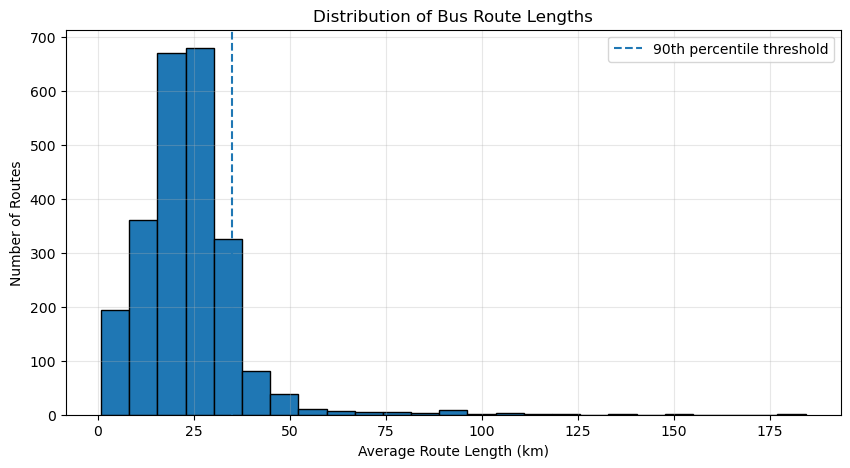

In [34]:
plt.figure(figsize=(10, 5))

plt.hist(
    split_features["avg_route_length_km"],
    bins=25,
    edgecolor="black"
)

plt.axvline(
    length_threshold,
    linestyle="--",
    label="90th percentile threshold"
)

plt.title("Distribution of Bus Route Lengths")
plt.xlabel("Average Route Length (km)")
plt.ylabel("Number of Routes")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

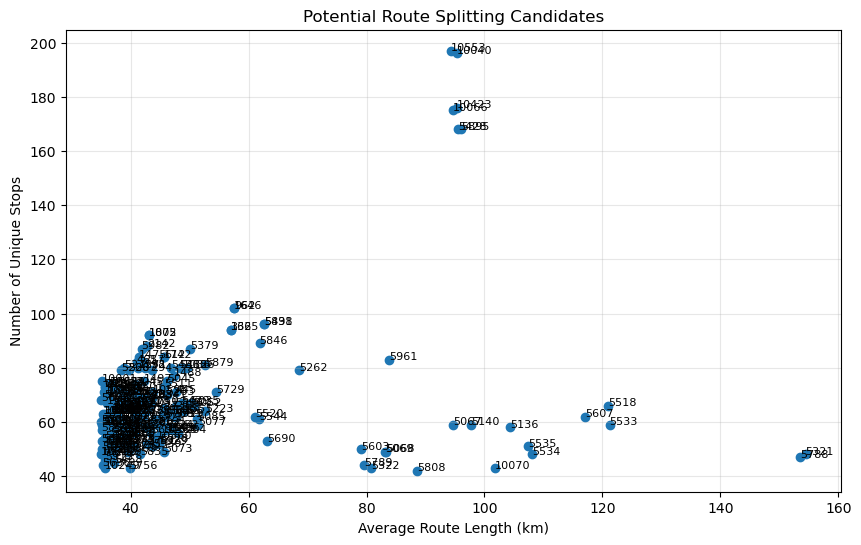

In [35]:
if not split_suggestions.empty:

    plt.figure(figsize=(10, 6))

    plt.scatter(
        split_suggestions["avg_route_length_km"],
        split_suggestions["total_unique_stops"]
    )

    for _, row in split_suggestions.iterrows():
        plt.annotate(
            str(row["route_id"]),
            (
                row["avg_route_length_km"],
                row["total_unique_stops"]
            ),
            fontsize=8
        )

    plt.title("Potential Route Splitting Candidates")
    plt.xlabel("Average Route Length (km)")
    plt.ylabel("Number of Unique Stops")
    plt.grid(alpha=0.3)

    plt.show()

else:
    print("No routes met all splitting criteria.")